### Import

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from msuthemes import theme_msu, colors


### Configuration of Paths, Variables, and Load Precomputed Results

In [11]:
# --- CONFIGURATION ---
RESULTS_DIR = "h1_results"
OUTPUT_PLOT = os.path.join(RESULTS_DIR, "Master_H1_Analysis.png")

signals = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']

# Custom mapping for clean plot titles
signal_titles = {
    'Gaze_X': 'Gaze X', 'Gaze_Y': 'Gaze Y', 
    'Pupil_Mean': 'Pupil Dilation', 'Heart_Rate': 'Heart Rate', 'GSR': 'GSR'
}

# Load the summary stats to put exact numbers in titles
stats_df = pd.read_csv(os.path.join(RESULTS_DIR, "h1_summary_stats.csv")).set_index('Signal')

### Set up Helper Functions and (Pre)Compute Results

/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future

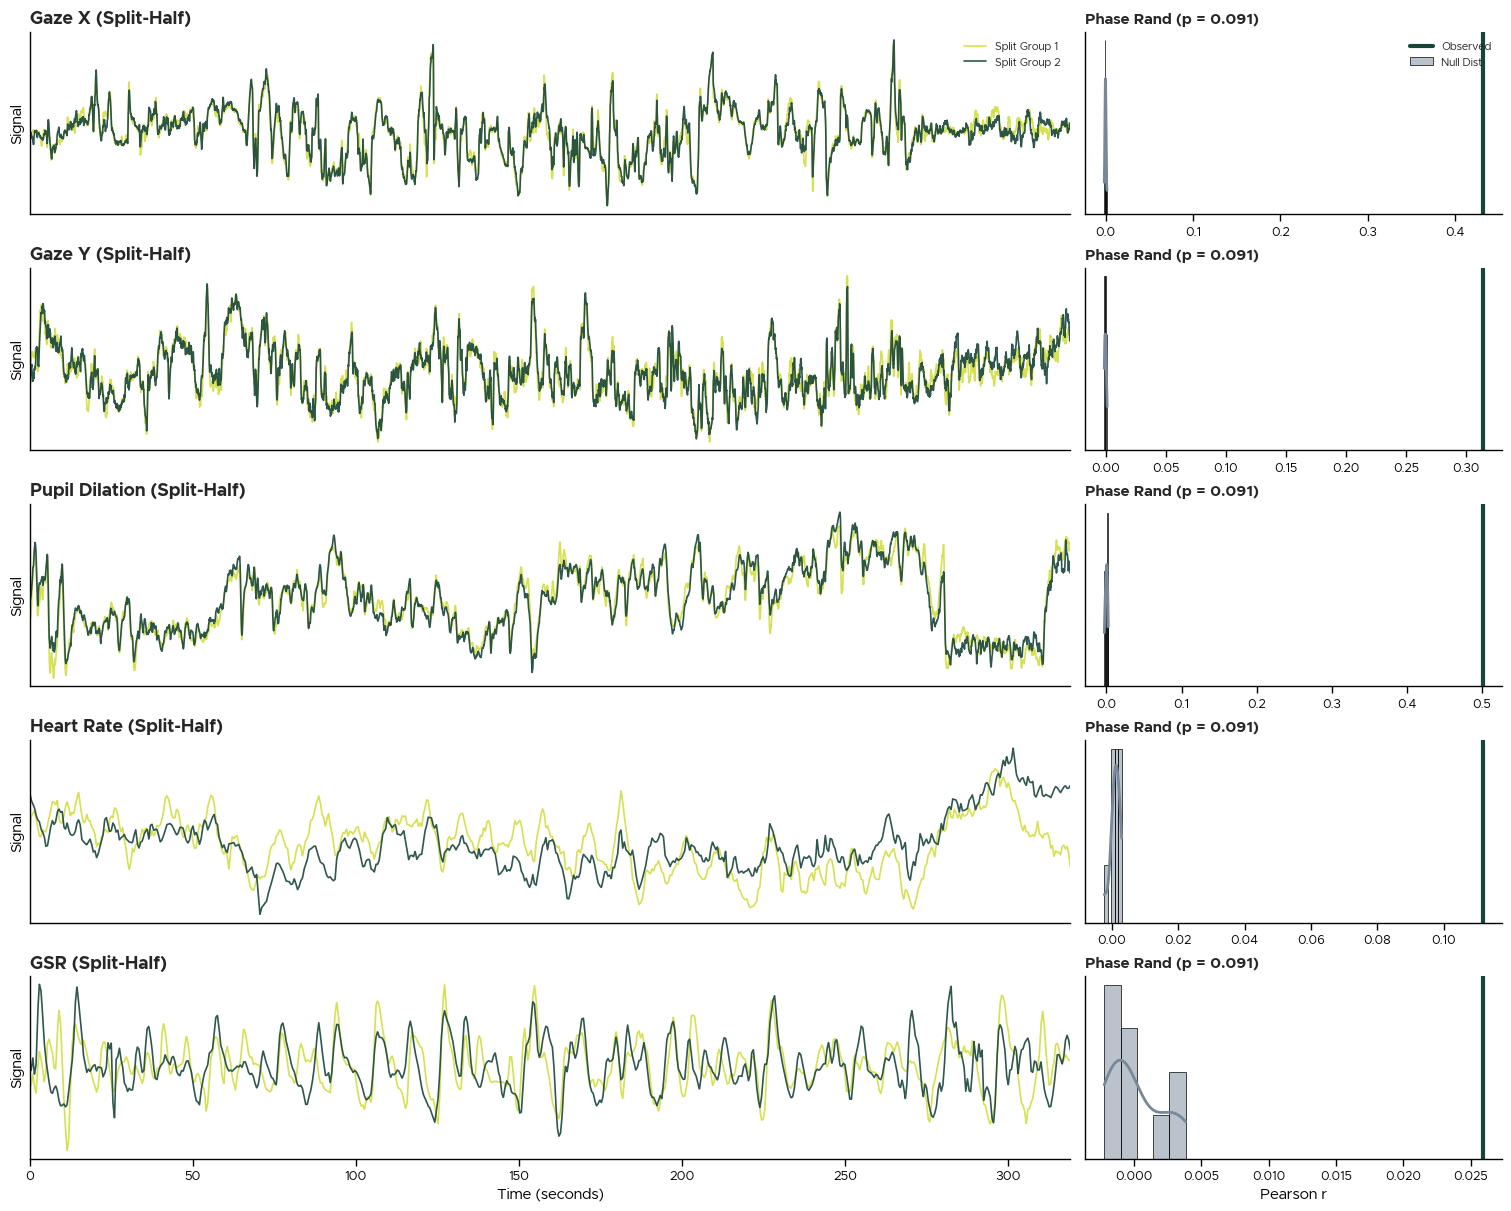

Final Master figure saved to h1_results/Master_H1_Analysis.png


In [17]:

sns.set(style="ticks", context="talk")
theme_msu()


# 1. Adjusted Ratio: 2.5 to 1 (Balanced)
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(15, 12), 
                         gridspec_kw={'width_ratios': [2.5, 1]}, 
                         constrained_layout=True)

for i, signal in enumerate(signals):
    
    # Get stats
    r_split = stats_df.loc[signal, 'Split_Half_r']
    obs_isc = stats_df.loc[signal, 'Observed_ISC']
    p_val = stats_df.loc[signal, 'Phase_Rand_P']
    
    # ==========================
    # LEFT COLUMN: TIMECOURSE
    # ==========================
    ax_tc = axes[i, 0]
    tc_df = pd.read_csv(os.path.join(RESULTS_DIR, f"{signal}_split_timecourse.csv"))
    
    ax_tc.plot(tc_df['Time_Sec'], tc_df['Group_1'], color=colors.MSU_GRELLOW, alpha=0.9, lw=1.2, label='Split Group 1')
    ax_tc.plot(tc_df['Time_Sec'], tc_df['Group_2'], color=colors.MSU_GREEN, alpha=0.9, lw=1.2, label='Split Group 2')
    
    # Title
    ax_tc.set_title(f"{signal_titles[signal]} (Split-Half)", fontweight='bold', fontsize=13, loc='left')
    
    # Clean Y-Axis (Remove Z-score labels)
    ax_tc.set_ylabel("Signal")   
    ax_tc.set_yticks([])   
    ax_tc.set_xlim(tc_df['Time_Sec'].min(), tc_df['Time_Sec'].max())
    
    # Clean X-Axis (Only show on bottom row)
    if i < 4: 
        ax_tc.set_xticklabels([])
        ax_tc.set_xlabel("")
        ax_tc.tick_params(bottom=False) # Hide the tick marks too
    else: 
        ax_tc.set_xlabel("Time (seconds)", fontsize=11)


    # ==========================
    # RIGHT COLUMN: HISTOGRAMS
    # ==========================
    ax_null = axes[i, 1]
    null_dist = np.load(os.path.join(RESULTS_DIR, f"{signal}_null_dist.npy"))
    
    sns.histplot(null_dist, kde=True, color='lightslategrey', alpha=0.5, ax=ax_null, label='Null Dist')
    ax_null.axvline(obs_isc, color= colors.MSU_GREEN, linestyle='-', linewidth=3, label='Observed')
    
    # Title
    p_str = "< .001" if p_val < 0.001 else f"= {p_val:.3f}"
    ax_null.set_title(f"Phase Rand (p {p_str})", fontweight='bold', fontsize=11, loc='left')
    
    # Clean Y-Axis
    ax_null.set_ylabel("") 
    ax_null.set_yticks([]) 
    
    # KEEP X-Axis for ALL rows (because scales differ)
    ax_null.tick_params(axis='x', labelsize=9) # Make numbers slightly smaller to fit
    # We only label the axis text on the bottom to save vertical space, 
    # but we keep the numbers (ticks) on all rows.
    if i == 4:
        ax_null.set_xlabel("Pearson r", fontsize=11)
    else:
        ax_null.set_xlabel("")

# --- FINAL TOUCHES ---
# Legends (First row only)
axes[0,0].legend(loc='upper right', fontsize=8, frameon=False)
axes[0,1].legend(loc='upper right', fontsize=8, frameon=False)

sns.despine()

plt.savefig(OUTPUT_PLOT, dpi=300)
plt.show()

print(f"Final Master figure saved to {OUTPUT_PLOT}")

In [ ]:
### OLDs

In [2]:
current_dir = os.getcwd()
CONDITIONS_FILE = os.path.abspath(os.path.join(current_dir, "../data/sub_conditions.csv"))
DATA_DIR        = os.path.abspath(os.path.join(current_dir, "../data/02_processed_combined_data"))

In [31]:
def parse_subject_id(respondent_name):
    """
    Extracts subject ID (e.g., 'sub001') from RespondentName string.
    Handles potential extra spaces or underscores.
    """
    # Split by underscore and take the first part
    parts = respondent_name.split('_')
    sub_id = parts[0].strip()
    return sub_id
    
def get_subjects_by_condition(conditions_file, target_condition='PC'):
    """
    Reads the conditions file and returns a list of subject IDs for the target condition.
    """
    if not os.path.exists(conditions_file):
        raise FileNotFoundError(f"Conditions file not found: {conditions_file}")
        
    df = pd.read_csv(conditions_file)
    
    # Clean column names just in case
    df.columns = [c.strip() for c in df.columns]
    
    if 'RespondentName' not in df.columns or 'SourceStimulus' not in df.columns:
        raise ValueError("Conditions file must contain 'RespondentName' and 'SourceStimulus' columns.")
    
    # Filter by condition
    condition_df = df[df['SourceStimulus'].str.strip() == target_condition].copy()
    
    subject_ids = condition_df['RespondentName'].apply(parse_subject_id).tolist()
    
    # Remove duplicates if any
    subject_ids = sorted(list(set(subject_ids)))
    
    #print(f"[{target_condition}] Found {len(subject_ids)} subjects in condition file.")
    return subject_ids

import pandas as pd
import glob
import os

def load_filtered_physiological_data(folder_path, subject_list):
    """
    Loads CSV files ONLY if they match an ID in subject_list.
    Checks for required columns and data integrity.
    Returns a dictionary of DataFrames (Time x Subjects).
    """
    
    required_cols = ['Time_sec', 'GSR', 'Heart_Rate', 'Pupil_Mean', 'Gaze_X', 'Gaze_Y']
    signal_types = ['GSR', 'Heart_Rate', 'Pupil_Mean', 'Gaze_X', 'Gaze_Y']
    
    # 1. Structure to hold data: {'GSR': [], 'Heart_Rate': [], ...}
    data_collector = {signal: [] for signal in signal_types}
    
    file_list = glob.glob(os.path.join(folder_path, "*.csv"))
    
    print(f"Scanning {len(file_list)} files against {len(subject_list)} subject IDs...")
    
    loaded_count = 0
    
    for filepath in file_list:
        filename = os.path.basename(filepath)
        
        # --- FILTER 1: CHECK FILENAME AGAINST LIST ---
        # We look for a subject ID that exists inside this filename.
        # e.g., if filename is 'sub003_combined_physio.csv' and 'sub003' is in the list
        matched_subject_id = None
        
        for subj_id in subject_list:
            if subj_id in filename:
                matched_subject_id = subj_id
                break # Found the match, stop checking other IDs
        
        # If this file doesn't match anyone in our list, skip it silently
        if matched_subject_id is None:
            continue

        try:
            # Load data
            df = pd.read_csv(filepath)
            
            # --- FILTER 2: CHECK COLUMN EXISTENCE ---
            if not set(required_cols).issubset(df.columns):
                print(f"Skipping {matched_subject_id} (File: {filename}) - Missing required columns")
                continue
            
            # --- FILTER 3: CHECK FOR EMPTY/NAN DATA ---
            # Check if any required column has NaN values
            if df[required_cols].isnull().any().any():
                print(f"Skipping {matched_subject_id} (File: {filename}) - Contains NaNs/Missing data")
                continue
                
            # --- PROCESSING ---
            # 1. Handle Time Index (Round to 3 decimals to ensure alignment across subjects)
            df['Time_sec'] = df['Time_sec'].round(3)
            df = df.set_index('Time_sec')
            
            # 2. Add each signal to its respective list
            for signal in signal_types:
                s = df[signal]
                s.name = matched_subject_id  # Column name becomes 'sub002', etc.
                data_collector[signal].append(s)
                
            loaded_count += 1
            
        except Exception as e:
            print(f"Error reading {filename}: {e}")

    print(f"Successfully loaded {loaded_count} valid subjects.")

    # --- MERGING ---
    final_dfs = {}
    for signal, series_list in data_collector.items():
        if series_list:
            # Concat aligns on the Index (Time_sec) automatically
            merged_df = pd.concat(series_list, axis=1)
            merged_df.sort_index(inplace=True)
            final_dfs[signal] = merged_df
        else:
            final_dfs[signal] = pd.DataFrame()

    return final_dfs

def plot_split_half_comparison(data_df, title="Split-Half Consistency", output_path=None):
    """
    Visualizes two random halves of the group to show consistency.
    """
    data = data_df.values
    n_subjects = data.shape[1]
    indices = np.arange(n_subjects)
    np.random.shuffle(indices)
    mid = n_subjects // 2
    
    g1 = data[:, indices[:mid]].mean(axis=1)
    g2 = data[:, indices[mid:]].mean(axis=1)

    # 3. Z-Score (Standardize) the Group Means
    # (x - mean) / std
    g1 = (g1 - np.mean(g1)) / np.std(g1)
    g2 = (g2 - np.mean(g2)) / np.std(g2)
    
    plt.figure(figsize=(5, 2))
    plt.plot(g1, color='dodgerblue', alpha=0.9, linewidth=1.5, label='Split Group 1')
    plt.plot(g2, color='darkorange', alpha=0.9, linewidth=1.5, label='Split Group 2')
    
    # Correlation between them
    r = np.corrcoef(g1, g2)[0, 1]
    
    plt.title(f"{title} (r = {r:.3f})")
    plt.xlabel("Time (samples)")
    plt.ylabel("Signal Amplitude")
    #plt.legend()
    plt.xlim(0, len(g1))
    plt.yticks([]) 

    sns.despine()
    
    plt.tight_layout()
    if output_path:
        plt.savefig(output_path, dpi=300)
        print(f"Split-half plot saved to {output_path}")
    plt.show()
    #plt.close()


import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

def analyze_split_half_distribution(data_df, n_permutations=5000):
    """
    Performs repeated random split-half reliability checks.
    Uses Fisher Z-transformation for correct averaging of correlations.
    """
    data = data_df.values
    n_timepoints, n_subjects = data.shape
    
    # Pre-allocate array
    r_values = np.zeros(n_permutations)
    
    # Indices setup
    indices = np.arange(n_subjects)
    mid = n_subjects // 2
    
    print(f"Running {n_permutations} permutations on {n_subjects} subjects...")
    
    for i in range(n_permutations):
        np.random.shuffle(indices)
        
        # Split data
        g1 = data[:, indices[:mid]].mean(axis=1)
        g2 = data[:, indices[mid:]].mean(axis=1)
        
        # Correlation
        r = np.corrcoef(g1, g2)[0, 1]
        
        # Clip r to avoid infinity in arctanh (extremely rare in real data but safer)
        r = np.clip(r, -0.999999, 0.999999)
        r_values[i] = r

    # --- Fisher Z-Transformation Step ---
    # 1. Transform all r values to z space
    z_values = np.arctanh(r_values)
    
    # 2. Calculate statistics in z space
    mean_z = np.mean(z_values)
    
    # 3. Transform back to r space
    fisher_mean_r = np.tanh(mean_z)
    
    # Note: Percentiles are invariant to monotonic transformations, 
    # so we can calculate CI on raw data or transform z-CI back. Both result in the same r value.
    ci_lower = np.percentile(r_values, 2.5)
    ci_upper = np.percentile(r_values, 97.5)
    
    # Simple arithmetic mean (for comparison/sanity check, usually lower than Fisher)
    arithmetic_mean_r = np.mean(r_values)

    print(f"Fisher-Z Mean r: {fisher_mean_r:.3f}")
    print(f"(Arithmetic Mean r: {arithmetic_mean_r:.3f})")
    print(f"95% CI: [{ci_lower:.3f}, {ci_upper:.3f}]")

    stats = {
        "mean_r": fisher_mean_r,
        "arithmetic_mean_r": arithmetic_mean_r,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "z_values": z_values # saving the z-scores if you need them for t-tests later
    }
    
    return stats, r_values

In [32]:
pc_subjs = get_subjects_by_condition(CONDITIONS_FILE, target_condition='PC') 

results = load_filtered_physiological_data(DATA_DIR, pc_subjs)
results
# # Access specific DataFrames
gazeX_data = results['Gaze_X']
gazeY_data = results['Gaze_Y']
pupil_data = results['Pupil_Mean']
hr_data = results['Heart_Rate']
gsr_data = results['GSR'] 

print(gazeX_data.shape)
print(gazeY_data.shape)
print(pupil_data.shape)
print(hr_data.shape)
print(gsr_data.shape)


Scanning 194 files against 99 subject IDs...
Successfully loaded 97 valid subjects.
(6381, 97)
(6381, 97)
(6381, 97)
(6381, 97)
(6381, 97)


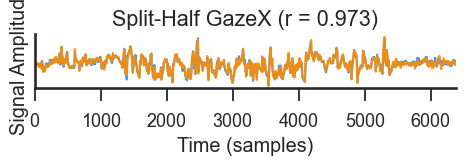

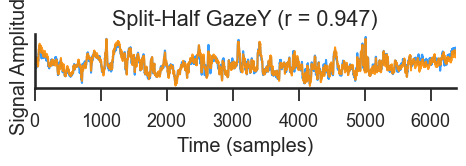

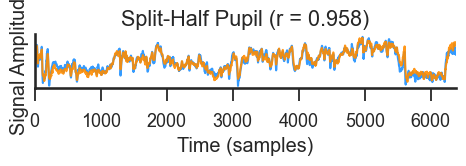

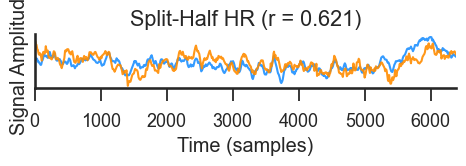

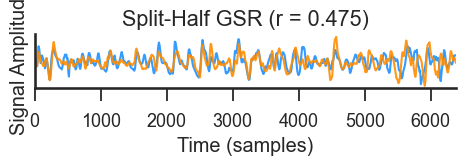

In [33]:
plot_split_half_comparison(gazeX_data, title="Split-Half GazeX")
plot_split_half_comparison(gazeY_data, title="Split-Half GazeY")
plot_split_half_comparison(pupil_data, title="Split-Half Pupil")
plot_split_half_comparison(hr_data, title="Split-Half HR")
plot_split_half_comparison(gsr_data, title="Split-Half GSR")

In [18]:
print("GazeX")
stats, dist = analyze_split_half_distribution(gazeX_data, n_permutations=5000)

print("\nGazeY")
stats, dist = analyze_split_half_distribution(gazeY_data, n_permutations=5000)

print("\nPupil")
stats, dist = analyze_split_half_distribution(pupil_data, n_permutations=5000)

print("\nHR")
stats, dist = analyze_split_half_distribution(hr_data, n_permutations=5000)

print("\nGSR")
stats, dist = analyze_split_half_distribution(gsr_data, n_permutations=5000)

GazeX
Running 5000 permutations on 97 subjects...
Fisher-Z Mean r: 0.968
(Arithmetic Mean r: 0.967)
95% CI: [0.953, 0.974]

GazeY
Running 5000 permutations on 97 subjects...
Fisher-Z Mean r: 0.950
(Arithmetic Mean r: 0.950)
95% CI: [0.937, 0.959]

Pupil
Running 5000 permutations on 97 subjects...
Fisher-Z Mean r: 0.962
(Arithmetic Mean r: 0.961)
95% CI: [0.942, 0.972]

HR
Running 5000 permutations on 97 subjects...
Fisher-Z Mean r: 0.702
(Arithmetic Mean r: 0.697)
95% CI: [0.554, 0.797]

GSR
Running 5000 permutations on 97 subjects...
Fisher-Z Mean r: 0.514
(Arithmetic Mean r: 0.512)
95% CI: [0.401, 0.609]


ISC GazeX: 0.43, p = 0.0002


/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


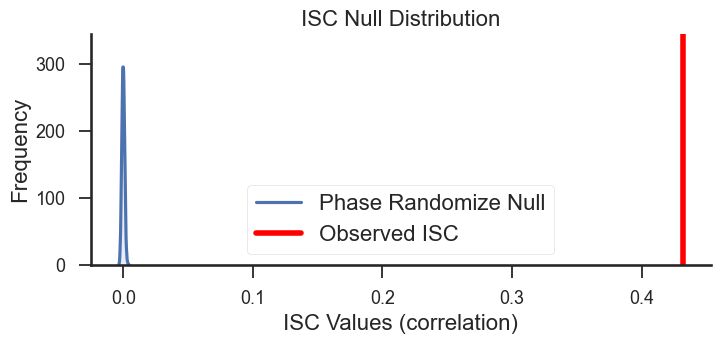

In [19]:
stats_phase = isc(gazeX_data, method='phase_randomize', n_samples=n_samples, return_null=True)
print(f"ISC GazeX: {stats_phase['isc']:.02}, p = {stats_phase['p']:.03}")

fs = 16

sns.set(style="ticks", context="talk")
plt.style.use("seaborn-v0_8-talk")

plt.figure(figsize=(8,3));

sns.histplot(stats_phase['null_distribution'], kde=True, label='Bootstrap');
plt.ylabel('Frequency', fontsize= fs);
plt.xlabel('ISC Values (correlation)', fontsize= fs);
plt.title('ISC Null Distribution', fontsize= fs);
plt.axvline(stats_phase['isc'], linestyle='-', color='red', linewidth=4);
plt.legend(['Phase Randomize Null', 'Observed ISC'], fontsize=fs);
sns.despine()    
plt.show()

ISC GazeY: 0.31, p = 0.0002


/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


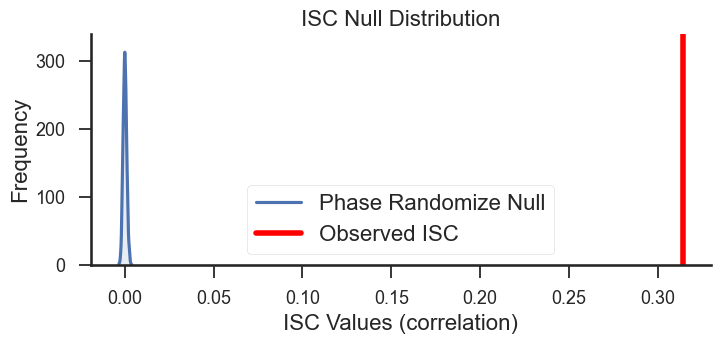

In [20]:
stats_phase = isc(gazeY_data, method='phase_randomize', n_samples=n_samples, return_null=True)
print(f"ISC GazeY: {stats_phase['isc']:.02}, p = {stats_phase['p']:.03}")

fs = 16

sns.set(style="ticks", context="talk")
plt.style.use("seaborn-v0_8-talk")

plt.figure(figsize=(8,3));

sns.histplot(stats_phase['null_distribution'], kde=True, label='Bootstrap');
plt.ylabel('Frequency', fontsize= fs);
plt.xlabel('ISC Values (correlation)', fontsize= fs);
plt.title('ISC Null Distribution', fontsize= fs);
plt.axvline(stats_phase['isc'], linestyle='-', color='red', linewidth=4);
plt.legend(['Phase Randomize Null', 'Observed ISC'], fontsize=fs);
sns.despine()    
plt.show()

ISC Pupil: 0.5, p = 0.0002


/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


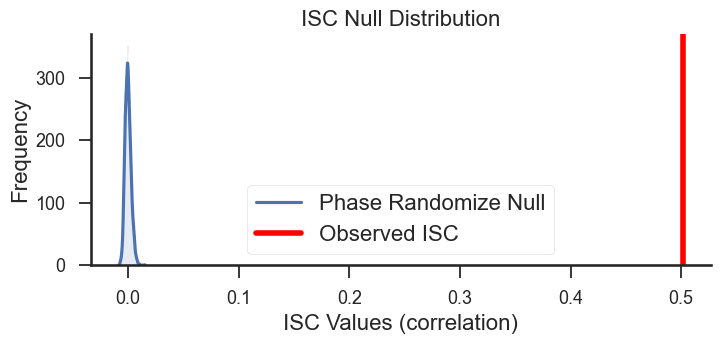

In [21]:
stats_phase = isc(pupil_data, method='phase_randomize', n_samples=n_samples, return_null=True)
print(f"ISC Pupil: {stats_phase['isc']:.02}, p = {stats_phase['p']:.03}")

fs = 16

sns.set(style="ticks", context="talk")
plt.style.use("seaborn-v0_8-talk")

plt.figure(figsize=(8,3));

sns.histplot(stats_phase['null_distribution'], kde=True, label='Bootstrap');
plt.ylabel('Frequency', fontsize= fs);
plt.xlabel('ISC Values (correlation)', fontsize= fs);
plt.title('ISC Null Distribution', fontsize= fs);
plt.axvline(stats_phase['isc'], linestyle='-', color='red', linewidth=4);
plt.legend(['Phase Randomize Null', 'Observed ISC'], fontsize=fs);
sns.despine()    
plt.show()

ISC HR: 0.11, p = 0.0002


/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


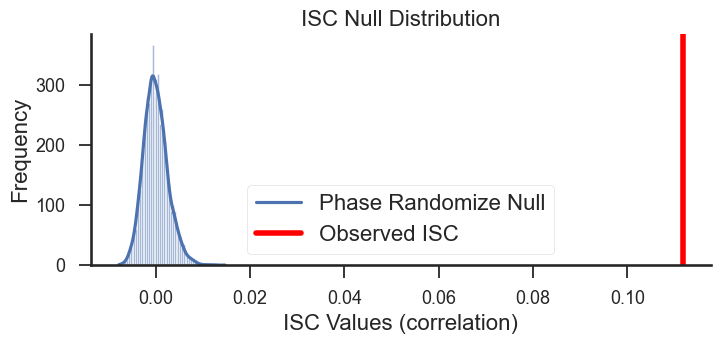

In [22]:
stats_phase = isc(hr_data, method='phase_randomize', n_samples=n_samples, return_null=True)
print(f"ISC HR: {stats_phase['isc']:.02}, p = {stats_phase['p']:.03}")

fs = 16

sns.set(style="ticks", context="talk")
plt.style.use("seaborn-v0_8-talk")

plt.figure(figsize=(8,3));

sns.histplot(stats_phase['null_distribution'], kde=True, label='Bootstrap');
plt.ylabel('Frequency', fontsize= fs);
plt.xlabel('ISC Values (correlation)', fontsize= fs);
plt.title('ISC Null Distribution', fontsize= fs);
plt.axvline(stats_phase['isc'], linestyle='-', color='red', linewidth=4);
plt.legend(['Phase Randomize Null', 'Observed ISC'], fontsize=fs);
sns.despine()    
plt.show()

ISC GSR: 0.026, p = 0.0002


/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


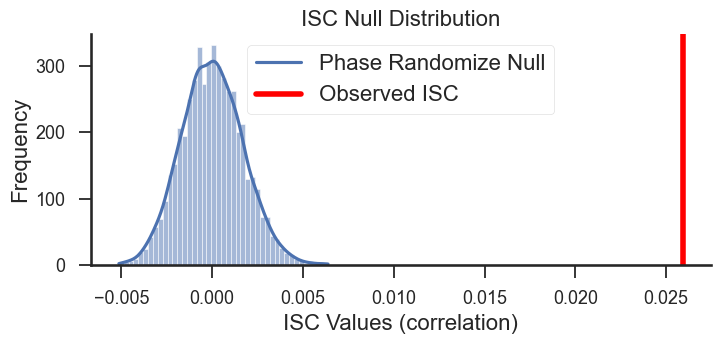

In [23]:
stats_phase = isc(gsr_data, method='phase_randomize', n_samples=n_samples, return_null=True)
print(f"ISC GSR: {stats_phase['isc']:.02}, p = {stats_phase['p']:.03}")

fs = 16

sns.set(style="ticks", context="talk")
plt.style.use("seaborn-v0_8-talk")

plt.figure(figsize=(8,3));

sns.histplot(stats_phase['null_distribution'], kde=True, label='Bootstrap');
plt.ylabel('Frequency', fontsize= fs);
plt.xlabel('ISC Values (correlation)', fontsize= fs);
plt.title('ISC Null Distribution', fontsize= fs);
plt.axvline(stats_phase['isc'], linestyle='-', color='red', linewidth=4);
plt.legend(['Phase Randomize Null', 'Observed ISC'], fontsize=fs);
sns.despine()    
plt.show()